# Inflammation markers and coronary heart disease (NHANES 2021-2023)

Foundations of Data Science, group project, dataset 5

## Part 1: Data cleaning, study sample, missing data and feature selection

Research question: Are NLR (neutrophil-to-lymphocyte ratio) and hs-CRP associated with self-reported coronary heart disease or heart attack (CHD/MI) in US adults, independent of the established risk factors? And do they improve the discrimination beyond these risk factors?

In this notebook we clean the data, build the variables and the study sample, look at the two markers, and decide how we handle missing values (E1) and which predictors we use (E2). The analysis sample is saved at the end for the next part (models and association analysis).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

import warnings
warnings.filterwarnings("ignore")

SEED = 42

## 1. Data cleaning

The raw file has 11,933 participants and 763 columns, and some values were made dirty on purpose. The metadata file has the allowed values for every column (`value_codes`), so we use it to clean all columns at once.

In [2]:
raw = pd.read_csv("../data/raw/nhanes_raw.csv", low_memory=False)
meta = pd.read_csv("../data/raw/nhanes_metadata.csv")
raw.shape

(11933, 763)

In [3]:
meta[["column_name", "sas_label", "value_codes"]].head()

,column_name,sas_label,value_codes
0,ACD010A,Speak English at home-Non-Hispanics,1=English | 77=Refused | 99=Don't know | .=Mis...
1,ACD010B,Speak Spanish at home-Non-Hispanics,8=Spanish | .=Missing
2,ACD010C,Other language at home-Non-Hispanics,9=Other | .=Missing
3,ACD040,Language(s) spoken at home-Hispanics,"1=Only Spanish, | 2=More Spanish than English ..."
4,WTPH2YR,Phlebotomy 2 Year Weight,6213.3002375 to 253478.77765=Range of Values |...


Example: the heart attack question MCQ160E. It should only contain 1, 2, 7 and 9.

In [4]:
print(meta.loc[meta["column_name"] == "MCQ160E", "value_codes"].values[0])
raw["MCQ160E"].value_counts(dropna=False)

1=Yes | 2=No | 7=Refused | 9=Don't know | .=Missing


MCQ160E
2.0                    7458
NaN                    4126
1.0                     332
9.0                      13
xvUXYNA                   1
Y                         1
999999.0                  1
2019-03-18T07:53:54       1
Name: count, dtype: int64

We found random text, timestamps and numbers like 999999 that are not in the codebook. There are also values like 5.4e-79 (the way SAS saves a 0) and the codes for "Refused" / "Don't know". The function below reads the `value_codes` of one column and returns the allowed ranges, the allowed codes and the non-response codes.

In [5]:
def read_codes(text):
    ranges, codes, nonresponse = [], [], []
    if not isinstance(text, str):
        return ranges, codes, nonresponse
    for part in text.split(" | "):
        code, _, label = part.partition("=")
        code, label = code.strip(), label.strip()
        if " to " in code:
            low, high = code.split(" to ")
            ranges.append((float(low), float(high)))
            continue
        try:
            value = float(code)
        except ValueError:   # "." or text codes like D=Day
            continue
        if label in ["Refused", "Don't know", "SP refusal", "Participant refusal"]:
            nonresponse.append(value)
        else:
            codes.append(value)
    return ranges, codes, nonresponse

In [6]:
read_codes("1=Yes | 2=No | 7=Refused | 9=Don't know | .=Missing")

([], [1.0, 2.0], [7.0, 9.0])

In [7]:
meta = meta.set_index("column_name")
clean = {}
n_text, n_nonresponse, n_outside = 0, 0, 0

for col in raw.columns:
    x = pd.to_numeric(raw[col], errors="coerce")
    n_text += (raw[col].notna() & x.isna()).sum()
    x[x.abs() < 1e-70] = 0

    if col in meta.index and col != "SEQN":
        ranges, codes, nonresponse = read_codes(meta.loc[col, "value_codes"])
        is_nonresponse = x.isin(nonresponse)
        n_nonresponse += is_nonresponse.sum()
        x[is_nonresponse] = np.nan

        if len(ranges) > 0 or len(codes) > 0:
            ok = x.isna() | x.isin(codes)
            for low, high in ranges:
                tol = 1e-6 * max(1, abs(high))   # the ranges in the codebook are rounded
                ok = ok | ((x >= low - tol) & (x <= high + tol))
            n_outside += (~ok).sum()
            x[~ok] = np.nan

    clean[col] = x

clean = pd.DataFrame(clean)
clean["SEQN"] = clean["SEQN"].astype(int)

print("text -> NaN:", n_text)
print("refused / don't know -> NaN:", n_nonresponse)
print("not in codebook -> NaN:", n_outside)

text -> NaN: 124640
refused / don't know -> NaN: 10439
not in codebook -> NaN: 92


In [8]:
clean["MCQ160E"].value_counts(dropna=False)

MCQ160E
2.0    7458
NaN    4143
1.0     332
Name: count, dtype: int64

## 2. Variables

Yes/no questions in NHANES are coded 1 = yes and 2 = no.

The outcome `chd_mi` is 1 if a doctor ever said the person had coronary heart disease (MCQ160C) or a heart attack (MCQ160E), and 0 if no to both. Angina is not part of the main outcome, we only use it in a sensitivity analysis later.

In [9]:
def yes_no(x):
    return x.map({1: 1.0, 2: 0.0})


df = pd.DataFrame({"SEQN": clean["SEQN"]})

df["chd"] = yes_no(clean["MCQ160C"])
df["mi"] = yes_no(clean["MCQ160E"])
df["angina"] = yes_no(clean["MCQ160D"])
df["chd_mi"] = np.nan
df.loc[(df["chd"] == 0) & (df["mi"] == 0), "chd_mi"] = 0
df.loc[(df["chd"] == 1) | (df["mi"] == 1), "chd_mi"] = 1

df["chd_mi"].value_counts(dropna=False)

chd_mi
0.0    7214
NaN    4160
1.0     559
Name: count, dtype: int64

The two markers: NLR is neutrophils % divided by lymphocytes %, hs-CRP is in mg/L.

In [10]:
df["crp"] = clean["LBXHSCRP"]
df["nlr"] = clean["LBXNEPCT"] / clean["LBXLYPCT"]

Established risk factors (from the risk scores PCE, SCORE2 and PREVENT): age, sex, race/ethnicity, income-to-poverty ratio, BMI, smoking, diabetes, hypertension, total and HDL cholesterol and eGFR. Age is top coded at 80 and income at 5.

In [11]:
df["age"] = clean["RIDAGEYR"]
df["male"] = clean["RIAGENDR"].map({1: 1.0, 2: 0.0})
race_names = {1: "mexican_american", 2: "other_hispanic", 3: "nh_white",
              4: "nh_black", 6: "nh_asian", 7: "other_multi"}
df["race_eth"] = clean["RIDRETH3"].map(race_names)
df["income_pir"] = clean["INDFMPIR"]
df["education"] = clean["DMDEDUC2"]
df["bmi"] = clean["BMXBMI"]

Smoking: never = less than 100 cigarettes in the whole life (SMQ020 = 2), former = smoked but not anymore, current = smokes every day or some days (SMQ040). For diabetes we count "borderline" (DIQ010 = 3) as no.

In [12]:
conditions = [clean["SMQ020"] == 2,
              (clean["SMQ020"] == 1) & (clean["SMQ040"] == 3),
              (clean["SMQ020"] == 1) & (clean["SMQ040"].isin([1, 2]))]
df["smoking"] = np.select(conditions, ["never", "former", "current"], default=None)

df["diabetes"] = clean["DIQ010"].map({1: 1.0, 2: 0.0, 3: 0.0})

Hypertension = told by a doctor or measured blood pressure >= 140/90 (mean of the three readings).

In [13]:
df["sbp"] = clean[["BPXOSY1", "BPXOSY2", "BPXOSY3"]].mean(axis=1)
df["dbp"] = clean[["BPXODI1", "BPXODI2", "BPXODI3"]].mean(axis=1)
df["told_htn"] = yes_no(clean["BPQ020"])

measured_high = ((df["sbp"] >= 140) | (df["dbp"] >= 90)).astype(float)
measured_high[df["sbp"].isna() & df["dbp"].isna()] = np.nan

df["hypertension"] = np.nan
df.loc[(df["told_htn"] == 0) & (measured_high == 0), "hypertension"] = 0
df.loc[(df["told_htn"] == 1) | (measured_high == 1), "hypertension"] = 1

eGFR with the CKD-EPI 2021 formula (the new version without race), creatinine in mg/dL.

In [14]:
df["total_chol"] = clean["LBXTC"]
df["hdl_chol"] = clean["LBDHDD"]

scr = clean["LBXSCR"]
kappa = np.where(df["male"] == 1, 0.9, 0.7)
alpha = np.where(df["male"] == 1, -0.302, -0.241)
female = np.where(df["male"] == 1, 1.0, 1.012)
df["egfr"] = 142 * np.minimum(scr / kappa, 1) ** alpha * np.maximum(scr / kappa, 1) ** -1.2 * 0.9938 ** df["age"] * female

We also keep lipid-lowering medication (BPQ101D, only for the sensitivity analysis, not as a predictor), the examination status and the survey design variables.

In [15]:
df["lipid_med"] = yes_no(clean["BPQ101D"])
df["exam_status"] = clean["RIDSTATR"]
df["weight_mec"] = clean["WTMEC2YR"]
df["strata"] = clean["SDMVSTRA"]
df["psu"] = clean["SDMVPSU"]

df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SEQN,11933.0,136344.00,3444.90,130378.00,133361.00,136344.00,139327.00,142310.00
chd,7773.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
mi,7790.0,0.04,0.20,0.00,0.00,0.00,0.00,1.00
angina,7783.0,0.02,0.15,0.00,0.00,0.00,0.00,1.00
chd_mi,7773.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00
crp,7282.0,3.43,7.18,0.11,0.60,1.45,3.65,165.63
nlr,7582.0,2.08,1.23,0.16,1.34,1.85,2.52,29.71
age,11933.0,38.32,25.60,0.00,13.00,37.00,62.00,80.00
male,11933.0,0.47,0.50,0.00,0.00,0.00,1.00,1.00
income_pir,9892.0,2.71,1.67,0.00,1.18,2.50,4.50,5.00


## 3. Study sample

Inclusion criteria:
1. age >= 20 (the heart questions are only asked from 20 on)
2. answered the CHD and heart attack questions
3. examined in the mobile examination center (MEC), where the blood was taken
4. NLR and hs-CRP measured

People with missing covariates are not excluded here, this is decided in section 5.

In [16]:
meta.loc["MCQ160C", "target_population"]

'Both males and females 20 YEARS - 150 YEARS'

In [17]:
flow = []

def add_step(name, data):
    flow.append({"step": name, "n": len(data), "cases": int((data["chd_mi"] == 1).sum())})

add_step("All participants", df)
adults = df[df["age"] >= 20]
add_step("Age >= 20", adults)
answered = adults[adults["chd_mi"].notna()].copy()
add_step("Answered CHD/MI questions", answered)
examined = answered[answered["exam_status"] == 2]
add_step("Examined in the MEC", examined)
sample = examined[examined["nlr"].notna() & examined["crp"].notna()].copy()
add_step("NLR and hs-CRP measured", sample)

flow = pd.DataFrame(flow)
flow["excluded"] = (-flow["n"].diff()).fillna(0).astype(int)
flow["prevalence %"] = (100 * flow["cases"] / flow["n"]).round(1)
flow

,step,n,cases,excluded,prevalence %
0,All participants,11933,559,0,4.7
1,Age >= 20,7809,559,4124,7.2
2,Answered CHD/MI questions,7773,559,36,7.2
3,Examined in the MEC,6037,451,1736,7.5
4,NLR and hs-CRP measured,5538,412,499,7.4


The analysis sample has 5,538 people and 412 cases (7.4 %).

### Who was excluded?

1,736 adults were not examined and 499 had no blood markers. We compare them with our sample using the standardized mean difference (SMD = difference of the means / pooled SD). An |SMD| above 0.1 is usually seen as a relevant difference.

In [18]:
def smd(a, b):
    a, b = a.dropna(), b.dropna()
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

In [19]:
answered["nh_white"] = (answered["race_eth"] == "nh_white").astype(float)
answered["nh_black"] = (answered["race_eth"] == "nh_black").astype(float)
answered["current_smoker"] = (answered["smoking"] == "current").astype(float)
answered.loc[answered["smoking"].isna(), "current_smoker"] = np.nan

in_sample = answered["SEQN"].isin(sample["SEQN"])
no_exam = answered["exam_status"] != 2
no_blood = ~no_exam & ~in_sample

rows = []
for var in ["age", "male", "income_pir", "education", "nh_white", "nh_black",
            "current_smoker", "diabetes", "told_htn", "lipid_med", "chd_mi"]:
    rows.append({"variable": var,
                 "no exam": smd(answered.loc[no_exam, var], answered.loc[in_sample, var]),
                 "no blood markers": smd(answered.loc[no_blood, var], answered.loc[in_sample, var])})
pd.DataFrame(rows).round(2)

,variable,no exam,no blood markers
0,age,-0.06,-0.08
1,male,-0.02,-0.06
2,income_pir,-0.09,-0.36
3,education,-0.18,-0.29
4,nh_white,-0.06,-0.20
5,nh_black,0.07,0.26
6,current_smoker,0.03,0.20
7,diabetes,-0.08,0.07
8,told_htn,-0.03,0.11
9,lipid_med,-0.15,-0.07


The people without blood markers have a lower income (SMD -0.36) and less education (-0.29), and they are more often non-Hispanic Black (0.26) and current smokers (0.20). The CHD/MI prevalence is about the same (0.01 and -0.05), and the people without an examination are more similar to our sample (biggest difference: education -0.18). So the exclusion should not change the outcome much, but people with a low income are a bit under-represented. We will mention this as a limitation.

## 4. Distribution of the markers

Lab values like these are often right-skewed. We considered three options: the raw values, a log transformation, or clinical categories (e.g. CRP < 1, 1-3, > 3 mg/L, but then we lose information). To decide, we look at the skewness, histograms and Q-Q plots (W3).

In [20]:
print("lowest values:", sample["nlr"].min().round(2), sample["crp"].min())
print("people with CRP = 0.11:", (sample["crp"] == 0.11).sum())

for col in ["nlr", "crp"]:
    print(col, "skewness raw:", round(stats.skew(sample[col]), 2), " log:", round(stats.skew(np.log(sample[col])), 2))

lowest values: 0.29 0.11
people with CRP = 0.11: 21
nlr skewness raw: 4.66  log: 0.15
crp skewness raw: 7.78  log: 0.23


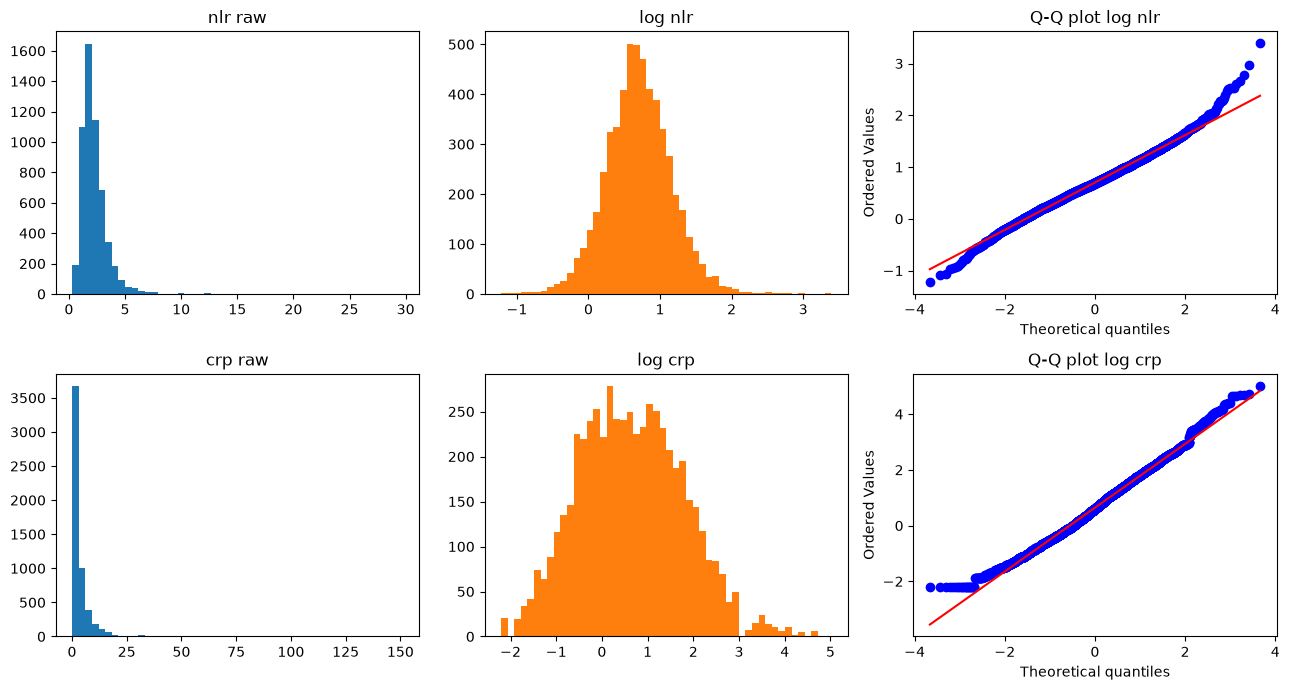

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for i, col in enumerate(["nlr", "crp"]):
    axes[i, 0].hist(sample[col], bins=50)
    axes[i, 0].set_title(col + " raw")
    axes[i, 1].hist(np.log(sample[col]), bins=50, color="tab:orange")
    axes[i, 1].set_title("log " + col)
    stats.probplot(np.log(sample[col]), dist="norm", plot=axes[i, 2])
    axes[i, 2].set_title("Q-Q plot log " + col)

plt.tight_layout()
plt.show()

On the raw scale both markers are very skewed (4.66 and 7.78). After the log the skewness is only 0.15 and 0.23, and the Q-Q plots are close to the line except for the tails. The flat part at the bottom left of the CRP plot are 21 people with exactly 0.11 mg/L, the lowest value in the codebook (probably the detection limit). We use the log values. This is important for LR, kNN and SVM, where a few extreme values would otherwise have a big influence.

We keep the outliers, on the log scale they are not extreme anymore. CRP above 10 mg/L (probably an acute infection) is checked in a sensitivity analysis.

In [22]:
sample["log_nlr"] = np.log(sample["nlr"])
sample["log_crp"] = np.log(sample["crp"])

# 1 SD of the log marker = factor on the original scale
print("NLR:", np.exp(sample["log_nlr"].std()).round(2))
print("CRP:", np.exp(sample["log_crp"].std()).round(2))

NLR: 1.58
CRP: 3.15


## 5. Missing data (E1)

As predictors we use the established risk factors (M2) and the two markers on top (M3). Lipid-lowering medication is not included, because most people get it after the diagnosis. Section 6 checks if a data-driven selection would be better.

In [23]:
M0 = ["age", "male"]
M1 = M0 + ["race_eth", "income_pir", "bmi"]
M2 = M1 + ["smoking", "diabetes", "hypertension", "total_chol", "hdl_chol", "egfr"]
M3 = M2 + ["log_nlr", "log_crp"]

In [24]:
missing = sample[M3].isna().sum().to_frame("n missing")
missing["%"] = (100 * missing["n missing"] / len(sample)).round(1)
missing.sort_values("n missing", ascending=False)

,n missing,%
income_pir,706,12.7
egfr,151,2.7
hypertension,107,1.9
total_chol,96,1.7
hdl_chol,96,1.7
bmi,74,1.3
smoking,7,0.1
age,0,0.0
race_eth,0,0.0
male,0,0.0


In [25]:
sample["complete"] = sample[M2].notna().all(axis=1)
print("complete cases:", sample["complete"].sum(), "people,", int(sample.loc[sample["complete"], "chd_mi"].sum()), "cases")

complete cases: 4563 people, 342 cases


Most variables have less than 3 % missing, but income has 12.7 %. With listwise deletion we would lose 975 people and 70 of the 412 cases.

First we check why income is missing (W2: MCAR, MAR, MNAR). We fit a logistic regression with "income missing" as the outcome.

In [26]:
d = sample.copy()
d["income_missing"] = d["income_pir"].isna().astype(int)
d["age10"] = d["age"] / 10

model = smf.logit("income_missing ~ age10 + male + C(race_eth, Treatment('nh_white')) + education"
                  " + C(smoking, Treatment('never')) + diabetes + hypertension + chd_mi"
                  " + log_nlr + log_crp", data=d).fit(disp=0)

pd.DataFrame({"OR": np.exp(model.params), "p": model.pvalues}).drop("Intercept").round(3)

,OR,p
"C(race_eth, Treatment('nh_white'))[T.mexican_american]",1.218,0.239
"C(race_eth, Treatment('nh_white'))[T.nh_asian]",1.314,0.121
"C(race_eth, Treatment('nh_white'))[T.nh_black]",1.577,0.000
"C(race_eth, Treatment('nh_white'))[T.other_hispanic]",1.535,0.001
"C(race_eth, Treatment('nh_white'))[T.other_multi]",1.045,0.811
"C(smoking, Treatment('never'))[T.current]",0.621,0.000
"C(smoking, Treatment('never'))[T.former]",0.840,0.085
age10,1.046,0.113
male,1.089,0.314
education,0.826,0.000


Income is missing more often for people with less education and for Black and Hispanic participants, so it is not MCAR. But it does not depend on CHD/MI (OR 1.03, p = 0.87) or on the markers. This fits MAR, the missingness can be explained by variables we have (MNAR can't be ruled out completely with the data).

We compare the three options from the W2 lecture:

A. listwise deletion (only people without missing values)

B. drop the income column and keep everybody

C. median imputation + a missing indicator `income_missing` (for categories the most frequent value)

Decision rule: we take C because it keeps everybody, unless A or B is more than 0.005 AUC better. The AUC is computed on the same test people for all three options, i.e. the complete cases of each test fold (A can't predict the others). Medians and scaling are learned on the training fold only. We use 5-fold CV repeated 2 times with logistic regression and random forest.

In [27]:
categorical = ["race_eth", "smoking"]
binary = ["male", "diabetes", "hypertension", "told_high_chol"]


def prepare(train, test, features, add_indicator=True):
    X_train = train[features].copy()
    X_test = test[features].copy()

    if add_indicator and "income_pir" in features:
        X_train["income_missing"] = X_train["income_pir"].isna().astype(int)
        X_test["income_missing"] = X_test["income_pir"].isna().astype(int)

    for col in features:
        if col in categorical or col in binary:
            fill = X_train[col].mode()[0]
        else:
            fill = X_train[col].median()
        X_train[col] = X_train[col].fillna(fill)
        X_test[col] = X_test[col].fillna(fill)

    cat_cols = [c for c in categorical if c in features]
    X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=float)
    X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=float)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    cont_cols = [c for c in features if c not in categorical and c not in binary]
    scaler = StandardScaler()
    X_train[cont_cols] = scaler.fit_transform(X_train[cont_cols])
    X_test[cont_cols] = scaler.transform(X_test[cont_cols])
    return X_train, X_test

In [28]:
y = sample["chd_mi"].astype(int).values
complete = sample["complete"].values

# stratify by outcome and complete/incomplete
strata = sample["chd_mi"].astype(int).astype(str) + "_" + sample["complete"].astype(str)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

options = {"A: listwise deletion": (M3, False, True),
           "B: drop income": ([f for f in M3 if f != "income_pir"], False, False),
           "C: median + indicator": (M3, True, False)}

e1 = []
for fold, (train_idx, test_idx) in enumerate(cv.split(sample, strata)):
    test = sample.iloc[test_idx]
    y_test = y[test_idx]
    cc_test = complete[test_idx]

    for option, (features, indicator, only_complete) in options.items():
        train = sample.iloc[train_idx]
        if only_complete:
            train = train[train["complete"]]
        X_train, X_test = prepare(train, test, features, add_indicator=indicator)

        models = {"LR": LogisticRegression(C=np.inf, max_iter=10000),
                  "RF": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1)}
        for name, clf in models.items():
            clf.fit(X_train, train["chd_mi"].astype(int))
            p = clf.predict_proba(X_test)[:, 1]
            row = {"fold": fold, "option": option, "model": name, "n_train": len(train),
                   "auc_complete": roc_auc_score(y_test[cc_test], p[cc_test])}
            if not only_complete:
                row["auc_with_gaps"] = roc_auc_score(y_test[~cc_test], p[~cc_test])
            e1.append(row)

e1 = pd.DataFrame(e1)
e1.groupby(["model", "option"])[["n_train", "auc_complete", "auc_with_gaps"]].mean().round(3)

n_train  auc_complete  auc_with_gaps
model option                                                     
LR    A: listwise deletion    3650.4         0.867            NaN
      B: drop income          4430.4         0.867          0.848
      C: median + indicator   4430.4         0.867          0.849
RF    A: listwise deletion    3650.4         0.865            NaN
      B: drop income          4430.4         0.865          0.833
      C: median + indicator   4430.4         0.866          0.836

`C=np.inf` means logistic regression without penalty. `auc_with_gaps` is the AUC for the test people with missing values, which only B and C can predict.

In [29]:
mean_auc = e1.groupby("option")["auc_complete"].mean()
print(mean_auc.round(4))

best_other = max(mean_auc["A: listwise deletion"], mean_auc["B: drop income"])
if best_other > mean_auc["C: median + indicator"] + 0.005:
    print("A or B is better")
else:
    print("no option is more than 0.005 better -> C")

option
A: listwise deletion     0.8657
B: drop income           0.8661
C: median + indicator    0.8665
Name: auc_complete, dtype: float64
no option is more than 0.005 better -> C


All three options give practically the same AUC (LR: 0.867 / 0.867 / 0.867, RF: 0.865 / 0.865 / 0.866), so deleting people doesn't help. With C we keep all 5,538 people and 412 cases, and the model can also predict people with missing values (AUC 0.84-0.85 for them). B would also keep everybody, but then income, a known risk factor, is gone. Decision: C, median imputation + missing indicator for income, always fitted inside the CV folds.

## 6. Feature selection (E2)

Should we choose the predictors from the literature or let an algorithm choose? From the lecture (W4, W6) we know filter, wrapper and embedded methods, lasso is an embedded method. We compare three strategies:

S1: the literature set M3 (13 variables), no selection

S2: all raw columns with at most 40 % missing, lasso chooses. This strategy is naive on purpose: every column is used as a number, also coded categories like race (RIDRETH3), exactly as an automatic selection would do it.

S3: a pool of 39 variables chosen by knowledge (M3 + 26 variables known to be related to heart disease, like blood pressure, waist, lab values, lifestyle, depression score), lasso chooses. Treatments, other heart diagnoses and health care use are not allowed in the pool.

The lasso penalty C is tuned with an inner 5-fold CV (GridSearchCV with log-loss), like in tutorial 8. Same 10 outer folds as in E1. Our research question asks about the markers beyond the established risk factors, so S1 is basically given by the question. E2 checks if another strategy would be clearly better.

Decision rule: we keep S1 unless another strategy (a) contains no variables that are a consequence or a treatment of CHD and (b) is more than 0.005 AUC better than S1 on the same folds, with a 95% confidence interval of the difference that does not include 0.

In [30]:
drop = ["SEQN", "MCQ160C", "MCQ160E", "WTINT2YR", "WTMEC2YR", "WTPH2YR", "WTSAF2YR",
        "WTSPF2YR", "WTSVOC2Y", "SDMVSTRA", "SDMVPSU", "SDDSRVYR", "RIDSTATR"]
X_s2 = clean.loc[sample.index].drop(columns=drop)
X_s2 = X_s2.loc[:, X_s2.isna().mean() <= 0.4]
X_s2 = X_s2.loc[:, X_s2.nunique() > 1]
X_s2.shape

(5538, 342)

For S3 we need some more variables. Most of them can be taken directly from the cleaned data.

In [31]:
idx = sample.index
simple = {"waist": "BMXWAIST", "glucose": "LBXSGL", "uric_acid": "LBXSUA", "albumin": "LBXSAL",
          "hemoglobin": "LBXHGB", "platelets": "LBXPLTSI", "rdw": "LBXRDW",
          "monocyte_pct": "LBXMOPCT", "eosinophil_pct": "LBXEOPCT", "vitamin_d": "LBXVIDMS",
          "sleep_hours": "SLD012", "sedentary_min": "PAD680"}
for name, col in simple.items():
    sample[name] = clean.loc[idx, col]

sample["pulse"] = clean.loc[idx, ["BPXOPLS1", "BPXOPLS2", "BPXOPLS3"]].mean(axis=1)
sample["told_high_chol"] = yes_no(clean.loc[idx, "BPQ080"])
sample["wbc"] = clean.loc[idx, "LBXWBCSI"].where(clean.loc[idx, "LBXWBCSI"] < 100)

sample["log_tg"] = np.log(clean.loc[idx, "LBXSTR"])
sample["log_ggt"] = np.log(clean.loc[idx, "LBXSGTSI"])
sample["log_alt"] = np.log(clean.loc[idx, "LBXSATSI"])
sample["log_cotinine"] = np.log(clean.loc[idx, "LBXCOT"])
sample["log_uacr"] = np.log1p(clean.loc[idx, "URDACT"])

Physical activity in minutes per week (moderate + 2 x vigorous). The unit columns (D/W/M/Y) are text, so they became NaN in the cleaning and we take them from the raw file.

In [32]:
to_week = {"D": 7, "W": 1, "M": 7 / 30.44, "Y": 7 / 365.25}

moderate = clean.loc[idx, "PAD790Q"] * raw.loc[idx, "PAD790U"].map(to_week) * clean.loc[idx, "PAD800"]
moderate[clean.loc[idx, "PAD790Q"] == 0] = 0
vigorous = clean.loc[idx, "PAD810Q"] * raw.loc[idx, "PAD810U"].map(to_week) * clean.loc[idx, "PAD820"]
vigorous[clean.loc[idx, "PAD810Q"] == 0] = 0
sample["log_activity"] = np.log1p(moderate + 2 * vigorous)

Alcohol: drinks per week = how often per week (ALQ121) x drinks per day (ALQ130). Depression score PHQ-9 = sum of the 9 questions, only if all are answered.

In [33]:
per_week = {0: 0, 1: 7, 2: 5.5, 3: 3.5, 4: 2, 5: 1, 6: 2.5 * 12 / 52, 7: 12 / 52,
            8: 9 / 52, 9: 4.5 / 52, 10: 1.5 / 52}
freq = clean.loc[idx, "ALQ121"].map(per_week)
drinks = freq * clean.loc[idx, "ALQ130"]
drinks[freq == 0] = 0
drinks[clean.loc[idx, "ALQ111"] == 2] = 0
sample["log_drinks_wk"] = np.log1p(drinks)

dpq = clean.loc[idx, [f"DPQ0{i}0" for i in range(1, 10)]]
sample["phq9"] = dpq.sum(axis=1)
sample.loc[dpq.isna().any(axis=1), "phq9"] = np.nan

In [34]:
extra = ["education", "waist", "sbp", "dbp", "pulse", "told_high_chol", "log_tg", "glucose",
         "uric_acid", "albumin", "log_ggt", "log_alt", "log_uacr", "log_cotinine", "wbc",
         "hemoglobin", "platelets", "rdw", "monocyte_pct", "eosinophil_pct", "vitamin_d",
         "sleep_hours", "sedentary_min", "log_activity", "log_drinks_wk", "phq9"]
S3_POOL = M3 + extra
print(len(S3_POOL), "variables, max. missing:", (100 * sample[S3_POOL].isna().mean()).max().round(1), "%")

39 variables, max. missing: 13.7 %


In [35]:
def original_name(col):
    for v in categorical:
        if col.startswith(v):
            return v
    if col == "income_missing":
        return "income_pir"
    return col

In [36]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = {"C": [0.003, 0.01, 0.03, 0.1, 0.3]}
lasso = LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000, random_state=SEED)

e2 = []
coefs_s2 = []
selected_s3 = []

for fold, (train_idx, test_idx) in enumerate(cv.split(sample, y)):
    train, test = sample.iloc[train_idx], sample.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # S1
    X_train, X_test = prepare(train, test, M3)
    lr = LogisticRegression(C=np.inf, max_iter=10000).fit(X_train, y_train)
    e2.append({"fold": fold, "strategy": "S1 literature", "n_selected": len(M3),
               "auc": roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1])})

    # S2
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    X_train = scaler.fit_transform(imputer.fit_transform(X_s2.iloc[train_idx]))
    X_test = scaler.transform(imputer.transform(X_s2.iloc[test_idx]))
    gs = GridSearchCV(lasso, grid, cv=inner_cv, scoring="neg_log_loss", n_jobs=-1)
    gs.fit(X_train, y_train)
    coefs = pd.Series(gs.best_estimator_.coef_[0], index=X_s2.columns)
    coefs_s2.append(coefs)
    e2.append({"fold": fold, "strategy": "S2 naive lasso", "n_selected": (coefs != 0).sum(),
               "auc": roc_auc_score(y_test, gs.predict_proba(X_test)[:, 1])})

    # S3
    X_train, X_test = prepare(train, test, S3_POOL)
    gs = GridSearchCV(lasso, grid, cv=inner_cv, scoring="neg_log_loss", n_jobs=-1)
    gs.fit(X_train, y_train)
    chosen = {original_name(c) for c in X_train.columns[gs.best_estimator_.coef_[0] != 0]}
    selected_s3.append(list(chosen))
    e2.append({"fold": fold, "strategy": "S3 hybrid lasso", "n_selected": len(chosen),
               "auc": roc_auc_score(y_test, gs.predict_proba(X_test)[:, 1])})

    print("fold", fold, "done")

e2 = pd.DataFrame(e2)
e2.groupby("strategy")[["auc", "n_selected"]].agg(["mean", "std"]).round(3)

fold 0 done


fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


fold 6 done


fold 7 done


fold 8 done


fold 9 done


auc        n_selected       
                  mean    std       mean    std
strategy                                       
S1 literature    0.862  0.012       13.0  0.000
S2 naive lasso   0.923  0.015      114.2  5.203
S3 hybrid lasso  0.869  0.016       34.9  1.287

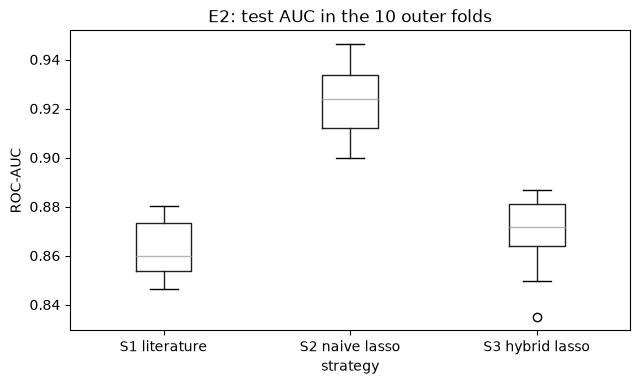

In [37]:
e2.boxplot(column="auc", by="strategy", grid=False, figsize=(7, 4))
plt.suptitle("")
plt.title("E2: test AUC in the 10 outer folds")
plt.ylabel("ROC-AUC")
plt.show()

The naive lasso (S2) looks much better with an AUC of 0.92. Which variables does it choose?

In [38]:
coefs_s2 = pd.DataFrame(coefs_s2)
share = (coefs_s2 != 0).mean()
print("chosen in all 10 folds:", (share == 1).sum(), " chosen at least once:", (share > 0).sum())

s2_table = pd.DataFrame({"share of folds": share, "mean abs coef": coefs_s2.abs().mean()})
top = s2_table.sort_values(["share of folds", "mean abs coef"], ascending=False).head(20)
top["label"] = [meta.loc[v, "sas_label"] for v in top.index]
top.round(3)

chosen in all 10 folds: 28  chosen at least once: 246


,share of folds,mean abs coef,label
RXQ510,1.0,0.531,Dr told to take daily low-dose aspirin?
MCQ160B,1.0,0.418,Ever told had congestive heart failure
RXQ050,1.0,0.353,Number of prescription medicines taken
OSQ230,1.0,0.338,Any metal objects inside your body?
MCQ160D,1.0,0.297,Ever told you had angina/angina pectoris
RIAGENDR,1.0,0.271,Gender
BPQ101D,1.0,0.216,Taking meds to lower blood cholesterol?
HUQ010,1.0,0.213,General health condition
RIDAGEYR,1.0,0.177,Age in years at screening
LBXTC,1.0,0.167,Total Cholesterol (mg/dL)


We went through the top 20 by hand and marked the variables that are a consequence or a treatment of the heart disease.

In [39]:
after_diagnosis = ["RXQ510", "MCQ160B", "RXQ050", "OSQ230", "MCQ160D", "BPQ101D", "HUQ010"]
top["after diagnosis"] = top.index.isin(after_diagnosis)
top["after diagnosis"].mean()

np.float64(0.35)

This is label leakage. The five strongest variables all come after the diagnosis: a doctor told them to take aspirin, heart failure, number of prescription medicines, metal objects in the body (stents) and angina. Lipid-lowering medication and the general health condition are also in the top 20. Someone with a stent obviously has CHD, so the model doesn't learn risk factors, it recognizes people who are already treated. The high AUC is not real and S2 can't answer our question.

The selection is also unstable: about 114 variables per fold, only 28 are chosen in all 10 folds but 246 at least once. Some make no sense at all, like the "comment code" of blood mercury.

In [40]:
freq_s3 = pd.Series([v for fold in selected_s3 for v in fold]).value_counts() / len(selected_s3)
freq_s3.reindex(S3_POOL).fillna(0).sort_values(ascending=False).round(1)

age               1.0
male              1.0
race_eth          1.0
diabetes          1.0
smoking           1.0
total_chol        1.0
hypertension      1.0
rdw               1.0
phq9              1.0
egfr              1.0
log_nlr           1.0
education         1.0
log_crp           1.0
waist             1.0
sbp               1.0
glucose           1.0
pulse             1.0
told_high_chol    1.0
log_tg            1.0
wbc               1.0
platelets         1.0
log_uacr          1.0
log_ggt           1.0
log_activity      1.0
monocyte_pct      1.0
log_alt           0.9
income_pir        0.9
sleep_hours       0.9
sedentary_min     0.8
dbp               0.8
uric_acid         0.8
log_drinks_wk     0.8
vitamin_d         0.7
albumin           0.7
hdl_chol          0.6
eosinophil_pct    0.6
log_cotinine      0.6
hemoglobin        0.5
bmi               0.3
Name: count, dtype: float64

To apply the rule we compare each strategy with S1 on the same 10 folds. The training sets of the folds overlap, so the normal standard error of the mean difference is too small. We use the correction of Nadeau and Bengio (2003), which we also need in part 2 for the model comparison.

In [41]:
def corrected_ci(diff, test_train_ratio=0.25):
    diff = np.asarray(diff)
    se = np.sqrt(1 / len(diff) + test_train_ratio) * diff.std(ddof=1)
    t = stats.t.ppf(0.975, len(diff) - 1)
    return diff.mean(), diff.mean() - t * se, diff.mean() + t * se


auc = e2.pivot(index="fold", columns="strategy", values="auc")
for s in ["S2 naive lasso", "S3 hybrid lasso"]:
    d, lo, hi = corrected_ci(auc[s] - auc["S1 literature"])
    print(f"{s} - S1: {d:+.4f} (95% CI {lo:+.4f} to {hi:+.4f})")

S2 naive lasso - S1: +0.0612 (95% CI +0.0499 to +0.0725)
S3 hybrid lasso - S1: +0.0066 (95% CI -0.0068 to +0.0199)


S3 is only slightly better than S1 (AUC 0.869 vs 0.862, +0.007, 95% CI -0.007 to +0.020) and uses about 35 variables instead of 13. It also keeps variables like urine albumin, RDW, the depression score or "ever told high cholesterol" that are not part of any risk score, which makes the model harder to interpret and to compare with clinical practice. Both markers are kept in every fold, so they contain some information, but this is tested properly in part 2.

Applying the rule: S2 fails (a) because of the leakage, even though it is +0.061 better. S3 passes (a), but its gain is not clearly above 0.005 (the confidence interval includes 0), so it fails (b).

Decision: S1, the literature set M3. It answers our question, it is the same in every fold and it contains no treatment variables. With the dummies M3 has 19 coefficients, so we have 412 / 19 = 21.7 events per parameter (rule of thumb: at least 10).

## 7. Save the analysis sample

The file is in `Final/data/`, which is not pushed to git (course data).

In [42]:
os.makedirs("data", exist_ok=True)
sample.to_csv("data/analysis_sample.csv", index=False)
sample.shape

(5538, 53)

## Summary and next steps

We cleaned all 763 columns with the codebook and have an analysis sample of 5,538 people with 412 cases. NLR and hs-CRP are used on the log scale. Missing values are handled with median imputation and a missing indicator for income (E1), and the predictors are the established risk factors M2, plus the two markers in M3 (E2).

For part 2: the preprocessing (function `prepare`) always has to be fitted inside the CV folds, and the main comparison is M2 vs M3. Planned sensitivity analyses: complete cases, adding lipid-lowering medication (Model 3), excluding CRP > 10 mg/L, survey weights, and the outcome including angina.